# Domain Corpus — Exploratory Data Analysis

**Purpose:** structural EDA on `domains_master.csv` — the domain *discovery and
classification* corpus for the Bangladesh TLS/PQC readiness study.

**Scope note (important):** this notebook analyzes what is already known about
each domain — its sector classification and verification confidence — not its
TLS configuration or liveness. No TLS scan has been run yet, so this notebook
cannot and does not report anything about which domains are actually reachable
or what their cryptographic posture is. That is a separate, later stage.

**Output:** all figures are saved to `report_figures/` as PNG files, and a
`eda_summary_report.md` file is generated at the end with the key numbers
written out in prose, ready to paste into the project document.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import re
import os

# ---- EDIT THIS PATH if your project folder is located elsewhere ----
DATA_PATH = "../data/processed/domains_master.csv"
FIG_DIR = "report_figures"

os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 10
plt.rcParams["savefig.bbox"] = "tight"


## 1. Load and validate

Basic sanity checks before any analysis: does the file load, are there
duplicate domains, are there any nulls. These should all come back clean if
`merge_and_dedupe.py` and the verification scripts ran correctly — if they
don't, that's worth investigating before trusting anything downstream in
this notebook.

In [2]:
df = pd.read_csv(DATA_PATH, dtype=str)

print(f"Rows loaded: {len(df):,}")
print(f"Columns: {list(df.columns)}")

n_dupes = df.duplicated(subset=["domain"]).sum()
n_null_domain = df["domain"].isna().sum()
n_null_sector = df["sector"].isna().sum()

print(f"\nExact duplicate domain rows: {n_dupes}")
print(f"Rows with a null domain: {n_null_domain}")
print(f"Rows with a null sector: {n_null_sector}")

if n_dupes > 0:
    print("\nWARNING: duplicates found. Showing a sample:")
    display(df[df.duplicated(subset=['domain'], keep=False)].sort_values('domain').head(10))


Rows loaded: 22,020
Columns: ['domain', 'source', 'date_added', 'sector', 'verification_note']

Exact duplicate domain rows: 0
Rows with a null domain: 0
Rows with a null sector: 0


## 2. Parse sector and confidence tier

The `sector` column encodes two things in one string, e.g.
`"university (institution-verified)"` — a **category** (university) and a
**confidence tier** (institution-verified). This splits them into separate
columns so they can be analyzed independently: how big is each sector, and
separately, how much of each sector is actually confirmed versus just
suffix-inferred.

Confidence tiers used across this project:
- **verified** — confirmed against an authoritative source (bank registry,
  UGC list, National Portal directory, administrative hierarchy dataset)
- **candidate (unverified)** — matched a keyword/heuristic but not yet
  checked against an authoritative source (e.g. banking keyword matches
  pending manual verification)
- **heuristic (unverified)** — suffix-based classification only, no
  authoritative source exists or was checked
- **low-confidence** — a heuristic match flagged as weak (e.g. generic
  substring match)
- **unclassified** — did not match any sector rule at all


In [3]:
def parse_sector(s):
    """Splits a sector string like "university (institution-verified)" into
    (category, confidence_tier). Handles the specific tier-label vocabulary
    used across this project's scripts (sector_tag.py, flag_finance_telecom.py,
    verify_against_source_list.py, repair_sector_labels.py)."""
    if pd.isna(s):
        return "unknown", "unknown"
    m = re.match(r"^([a-zA-Z]+)\s*(?:\((.+)\))?$", s.strip())
    if not m:
        return s, "unknown"
    category = m.group(1)
    detail = m.group(2) or ""
    if "institution-verified" in detail or "source-verified" in detail:
        tier = "verified"
    elif "rejected" in detail:
        tier = "rejected (confirmed false positive)"
    elif "LOW CONFIDENCE" in detail:
        tier = "low-confidence"
    elif "keyword match" in detail or "review manually" in detail:
        tier = "candidate (unverified)"
    elif "not verified" in detail or "heuristic" in detail:
        tier = "heuristic (unverified)"
    elif detail == "":
        tier = "unclassified"
    else:
        tier = "other"
    return category, tier

parsed = df["sector"].apply(parse_sector)
df["category"] = parsed.apply(lambda x: x[0])
df["confidence_tier"] = parsed.apply(lambda x: x[1])

# Flag anything that fell into "other" -- the regex above should cover every
# label actually in use; if this is non-empty, a new label format was
# introduced somewhere upstream and this parser needs updating to match.
other_rows = df[df["confidence_tier"] == "other"]
if len(other_rows) > 0:
    print(f"WARNING: {len(other_rows)} rows had an unrecognized sector format:")
    display(other_rows[["domain", "sector"]].head(10))
else:
    print("All sector values parsed into a known category/tier combination.")


All sector values parsed into a known category/tier combination.


## 3. Sector composition

In [4]:
cat_counts = df["category"].value_counts()
print(cat_counts.to_string())
print(f"\nTotal: {cat_counts.sum():,}")


category
university      16104
government       3999
commercial       1561
unclassified      233
banking            80
telecom            28
defence            15

Total: 22,020


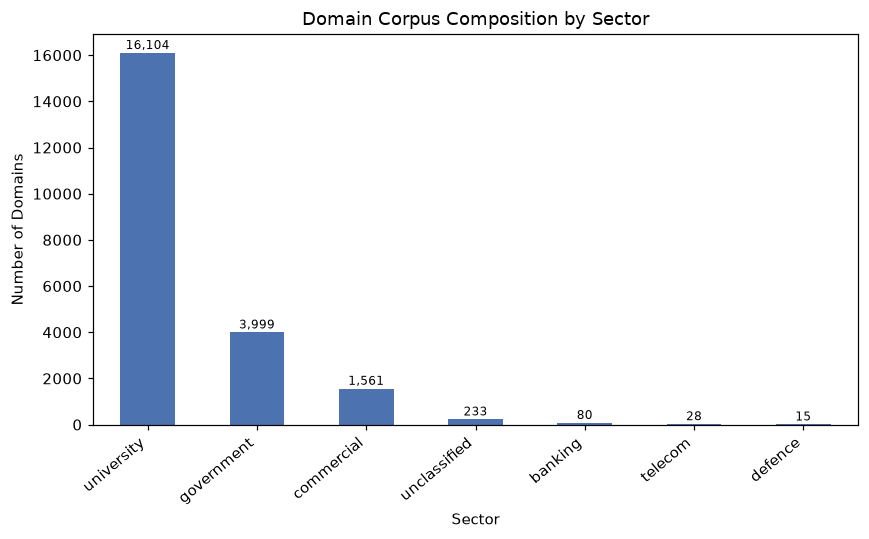

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
cat_counts.plot(kind="bar", ax=ax, color="#4C72B0")
ax.set_title("Domain Corpus Composition by Sector")
ax.set_xlabel("Sector")
ax.set_ylabel("Number of Domains")
for i, v in enumerate(cat_counts):
    ax.text(i, v + cat_counts.max() * 0.01, f"{v:,}", ha="center", fontsize=8)
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/01_sector_counts.png")
plt.show()


## 4. Verification confidence, overall and by sector

This is the most important structural finding for the document: not every
domain in the corpus is confirmed to the same standard. This section makes
that visible rather than treating the corpus as uniformly verified.

In [6]:
tier_by_sector = pd.crosstab(df["category"], df["confidence_tier"])
display(tier_by_sector)


confidence_tier,candidate (unverified),heuristic (unverified),rejected (confirmed false positive),unclassified,verified
category,,,,,
banking,6,0,9,0,65
commercial,1561,0,0,0,0
defence,0,15,0,0,0
government,0,2512,0,0,1487
telecom,0,0,0,0,28
unclassified,0,0,0,233,0
university,0,2978,0,0,13126


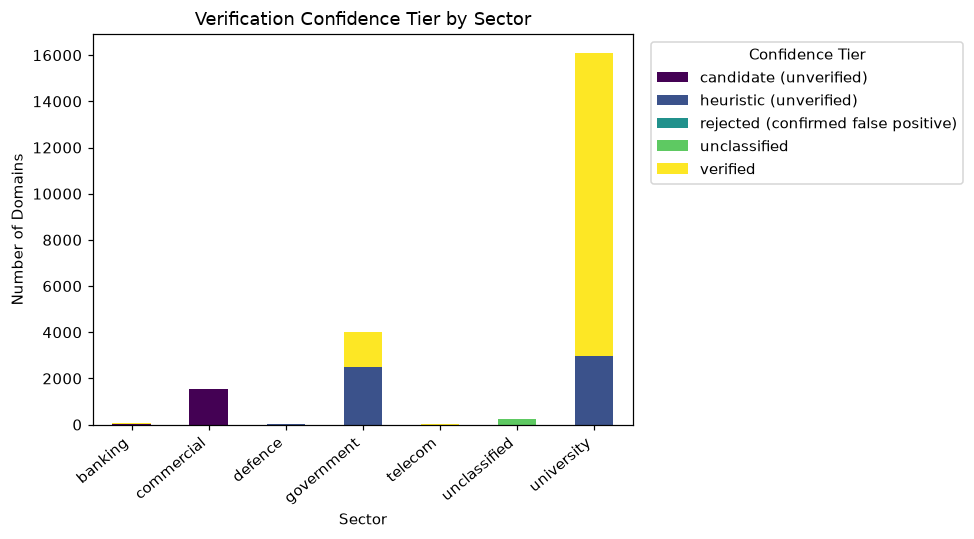

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
tier_by_sector.plot(kind="bar", stacked=True, ax=ax, colormap="viridis")
ax.set_title("Verification Confidence Tier by Sector")
ax.set_xlabel("Sector")
ax.set_ylabel("Number of Domains")
plt.xticks(rotation=40, ha="right")
plt.legend(title="Confidence Tier", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/02_verification_tier_by_sector.png")
plt.show()


The chart above shares one linear y-axis across all sectors, so small sectors (banking, telecom, defence) are compressed to a sliver next to university's ~16,000 domains and their tier segments aren't distinguishable by eye. The chart below shows the same data re-normalized so each sector's bar is scaled to 100% -- it shows **proportion of each sector**, not absolute domain count; read it alongside the chart above, not instead of it.

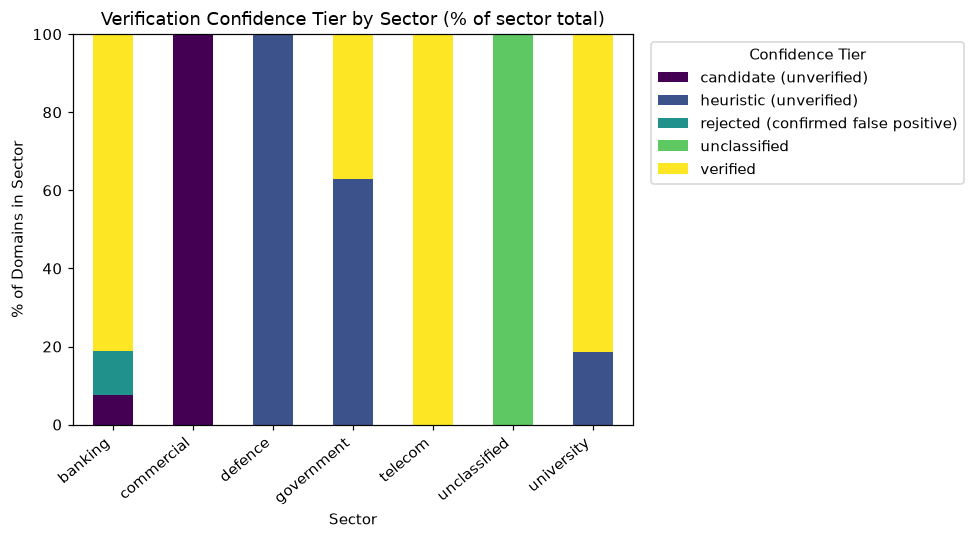

In [8]:
tier_pct_by_sector = tier_by_sector.div(tier_by_sector.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(9, 5))
tier_pct_by_sector.plot(kind="bar", stacked=True, ax=ax, colormap="viridis")
ax.set_title("Verification Confidence Tier by Sector (% of sector total)")
ax.set_xlabel("Sector")
ax.set_ylabel("% of Domains in Sector")
plt.xticks(rotation=40, ha="right")
plt.legend(title="Confidence Tier", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/02b_verification_tier_by_sector_pct.png")
plt.show()


Overall verified: 14,706 (66.8%)
Overall not verified: 7,314 (33.2%)


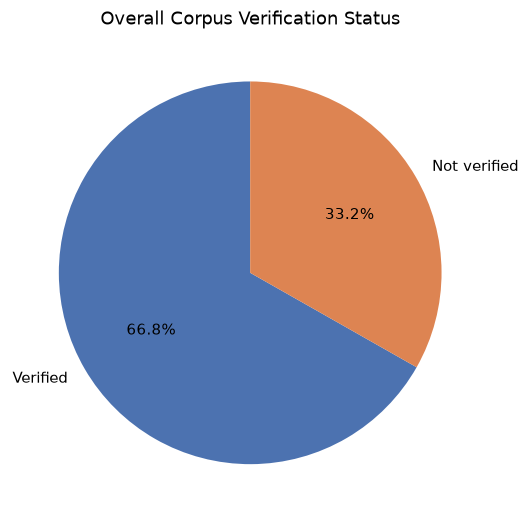

In [9]:
overall_tier = df["confidence_tier"].apply(lambda t: "Verified" if t == "verified" else "Not verified")
overall_counts = overall_tier.value_counts()
overall_pct_verified = overall_counts.get("Verified", 0) / len(df) * 100

print(f"Overall verified: {overall_counts.get('Verified', 0):,} ({overall_pct_verified:.1f}%)")
print(f"Overall not verified: {overall_counts.get('Not verified', 0):,} ({100 - overall_pct_verified:.1f}%)")

fig, ax = plt.subplots(figsize=(5, 5))
ax.pie(overall_counts, labels=overall_counts.index, autopct="%1.1f%%",
       startangle=90, colors=["#4C72B0", "#DD8452"])
ax.set_title("Overall Corpus Verification Status")
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/03_overall_verification_pie.png")
plt.show()


## 5. Domain suffix distribution

Cross-check: does the suffix distribution match what the sector classification
implies? (e.g. the "university" category should be almost entirely `.ac.bd`
and `.edu.bd`.) A mismatch here would indicate a classification bug worth
investigating before this data goes into the document.

In [10]:
def get_suffix(domain):
    if pd.isna(domain):
        return "unknown"
    parts = domain.strip().lower().split(".")
    if len(parts) >= 2:
        return "." + ".".join(parts[-2:])
    return domain

df["suffix"] = df["domain"].apply(get_suffix)
top_suffix = df["suffix"].value_counts().head(10)
print(top_suffix.to_string())


suffix
.ac.bd        8342
.edu.bd       7763
.gov.bd       3999
.com.bd       1660
.org.bd        162
.net.bd         61
.mil.bd         15
.info.bd         5
.mygov.bd        3
.webapp.bd       1


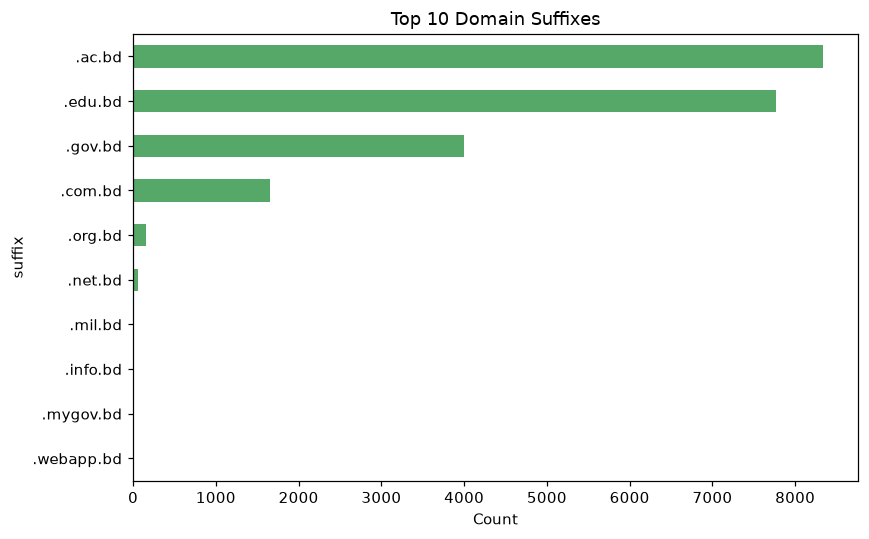

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
top_suffix.plot(kind="barh", ax=ax, color="#55A868")
ax.set_title("Top 10 Domain Suffixes")
ax.set_xlabel("Count")
ax.invert_yaxis()
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/04_top_suffixes.png")
plt.show()


## 6. Discovery source distribution

Which raw source file each domain was first identified from.

source
ac_bd_paginated_2026-09-14.json     6587
edu_bd_paginated_2026-09-14.json    5221
gov_bd_2026-09-13.json              2489
edu_bd_2026-09-13.json              2309
ac_bd_2026-09-13.json               1695
domcop_top10m                       1282
com_bd_2026-09-13.json               765
gov_bd_paginated_2026-09-14.json     644
tranco_bd_2026-09-13.txt             590
all_bd_2026-09-13.json               438


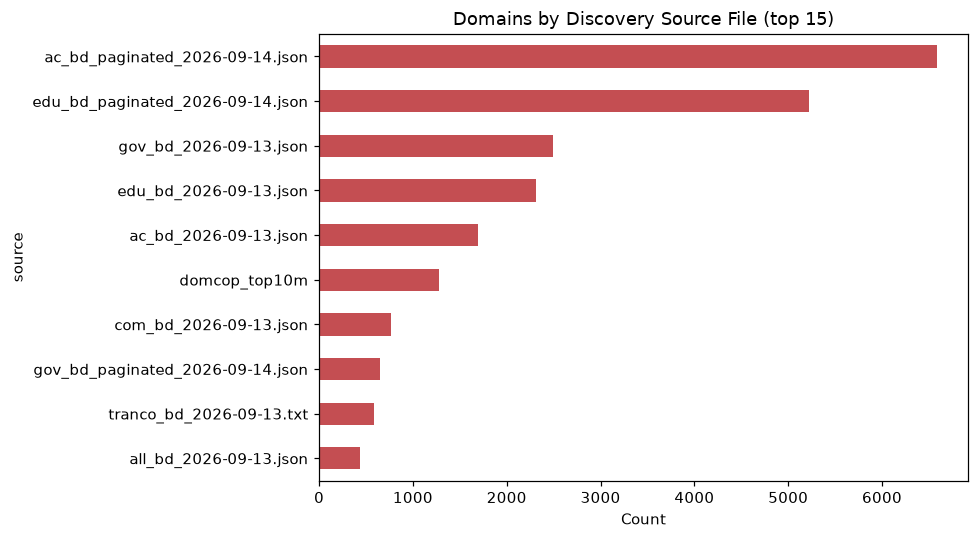

In [12]:
source_counts = df["source"].value_counts().head(15)
print(source_counts.to_string())

fig, ax = plt.subplots(figsize=(9, 5))
source_counts.plot(kind="barh", ax=ax, color="#C44E52")
ax.set_title("Domains by Discovery Source File (top 15)")
ax.set_xlabel("Count")
ax.invert_yaxis()
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/05_source_distribution.png")
plt.show()


## 7. Generate summary report

Writes `eda_summary_report.md` — the key numbers from this notebook in
prose form, ready to copy into the project document's corpus-status
section. Re-run this cell any time the underlying data changes to keep
the report current; it always reflects whatever is in `domains_master.csv`
at the time it's run, not a cached snapshot.

In [13]:
total = len(df)
verified_total = int((df["confidence_tier"] == "verified").sum())
verified_pct = verified_total / total * 100

report_lines = []
report_lines.append("# Domain Corpus — EDA Summary\n")
report_lines.append(f"Generated from `domains_master.csv` ({total:,} total rows).\n")

report_lines.append("## Sector composition\n")
report_lines.append("| Sector | Total | Verified | % Verified |")
report_lines.append("|---|---|---|---|")
for cat in cat_counts.index:
    cat_total = int(cat_counts[cat])
    cat_verified = int(tier_by_sector.loc[cat, "verified"]) if "verified" in tier_by_sector.columns and cat in tier_by_sector.index else 0
    pct = (cat_verified / cat_total * 100) if cat_total else 0
    report_lines.append(f"| {cat} | {cat_total:,} | {cat_verified:,} | {pct:.0f}% |")
report_lines.append(f"| **Total** | **{total:,}** | **{verified_total:,}** | **{verified_pct:.0f}%** |\n")

report_lines.append("## Data quality\n")
report_lines.append(f"- Exact duplicate domain rows: {n_dupes}")
report_lines.append(f"- Rows with unrecognized sector format: {len(other_rows)}")
report_lines.append(f"- Top suffix: `{top_suffix.index[0]}` ({top_suffix.iloc[0]:,} domains)\n")

report_lines.append("## Figures generated\n")
for fname, desc in [
    ("01_sector_counts.png", "Domain corpus composition by sector"),
    ("02_verification_tier_by_sector.png", "Verification confidence tier by sector"),
    ("03_overall_verification_pie.png", "Overall corpus verification status"),
    ("04_top_suffixes.png", "Top 10 domain suffixes"),
    ("05_source_distribution.png", "Domains by discovery source file"),
]:
    report_lines.append(f"- `{FIG_DIR}/{fname}` — {desc}")

report_lines.append("\n## Scope note\n")
report_lines.append(
    "This summary describes domain *discovery and classification* only. "
    "No TLS scan has been run against this corpus; liveness, reachability, "
    "and cryptographic configuration are not covered here and are addressed "
    "in a later stage of the project."
)

report_text = "\n".join(report_lines)
with open("eda_summary_report.md", "w") as f:
    f.write(report_text)

print(report_text)


# Domain Corpus — EDA Summary

Generated from `domains_master.csv` (22,020 total rows).

## Sector composition

| Sector | Total | Verified | % Verified |
|---|---|---|---|
| university | 16,104 | 13,126 | 82% |
| government | 3,999 | 1,487 | 37% |
| commercial | 1,561 | 0 | 0% |
| unclassified | 233 | 0 | 0% |
| banking | 80 | 65 | 81% |
| telecom | 28 | 28 | 100% |
| defence | 15 | 0 | 0% |
| **Total** | **22,020** | **14,706** | **67%** |

## Data quality

- Exact duplicate domain rows: 0
- Rows with unrecognized sector format: 0
- Top suffix: `.ac.bd` (8,342 domains)

## Figures generated

- `report_figures/01_sector_counts.png` — Domain corpus composition by sector
- `report_figures/02_verification_tier_by_sector.png` — Verification confidence tier by sector
- `report_figures/03_overall_verification_pie.png` — Overall corpus verification status
- `report_figures/04_top_suffixes.png` — Top 10 domain suffixes
- `report_figures/05_source_distribution.png` — Domains by discovery sourc